In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
import pandas as pd

file_path = "../data/food_delivery.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 1000
Columns: 15


,Order_ID,Order_Date,Customer_ID,Customer_Name,City,Restaurant,Category,Item,Quantity,Price,Total_Amount,Payment_Mode,Delivery_Time_Min,Order_Status,Rating
0,FD10001,2026-01-17,C1008,Rahul,Mumbai,Tasty Treats,Desserts,Gulab Jamun,1,219,219,Card,NaN,Cancelled,NaN
1,FD10002,2026-05-23,C1040,Neha,Nashik,Spice Villa,Chinese,Veg Noodles,2,290,580,UPI,64.0,Delivered,3.8
2,FD10003,2026-02-10,C1142,Amit,Thane,Cafe Delight,South Indian,Masala Dosa,3,91,273,Card,NaN,Cancelled,NaN
3,FD10004,2026-11-22,C1214,Vikas,Mumbai,Cafe Delight,Burger,Veg Burger,1,194,194,Cash,NaN,Cancelled,NaN
4,FD10005,2026-05-19,C1237,Riya,Mumbai,Cafe Delight,Burger,Cheese Burger,1,282,282,UPI,NaN,Cancelled,NaN


In [6]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(1000, 15)

Column Names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'City', 'Restaurant', 'Category', 'Item', 'Quantity', 'Price', 'Total_Amount', 'Payment_Mode', 'Delivery_Time_Min', 'Order_Status', 'Rating']

Data Types:
Order_ID                 str
Order_Date               str
Customer_ID              str
Customer_Name            str
City                     str
Restaurant               str
Category                 str
Item                     str
Quantity               int64
Price                  int64
Total_Amount           int64
Payment_Mode             str
Delivery_Time_Min    float64
Order_Status             str
Rating               float64
dtype: object

Missing Values:
Order_ID               0
Order_Date             0
Customer_ID            0
Customer_Name          0
City                   0
Restaurant             0
Category               0
Item                   0
Quantity               0
Price                  0
Total_Amount           0
Paym

In [7]:
# Convert date column to datetime
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

# Convert numeric columns
numeric_columns = [
    "Quantity",
    "Price",
    "Total_Amount",
    "Delivery_Time_Min",
    "Rating"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check duplicate rows
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)
print("Data cleaning completed successfully!")

Duplicate rows: 0
Data cleaning completed successfully!


In [8]:
# Check missing values after data cleaning

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:")
print(missing_values.sum())

Missing Values in Each Column:
Order_ID               0
Order_Date             0
Customer_ID            0
Customer_Name          0
City                   0
Restaurant             0
Category               0
Item                   0
Quantity               0
Price                  0
Total_Amount           0
Payment_Mode           0
Delivery_Time_Min    238
Order_Status           0
Rating               238
dtype: int64

Total Missing Values:
476


In [9]:
# Analyze missing values by order status

print("Missing values by Order Status:\n")

print(
    df.groupby("Order_Status")[["Delivery_Time_Min", "Rating"]]
      .apply(lambda x: x.isnull().sum())
)

print("\nOrder Status Count:")
print(df["Order_Status"].value_counts())

Missing values by Order Status:

              Delivery_Time_Min  Rating
Order_Status                           
Cancelled                   238     238
Delivered                     0       0

Order Status Count:
Order_Status
Delivered    762
Cancelled    238
Name: count, dtype: int64


In [10]:
# Basic Business KPIs

total_orders = len(df)
total_revenue = df["Total_Amount"].sum()
total_quantity = df["Quantity"].sum()
average_order_value = df["Total_Amount"].mean()

print("===== FOOD DELIVERY KPIs =====")
print(f"Total Orders       : {total_orders}")
print(f"Total Revenue      : ₹{total_revenue:,.2f}")
print(f"Total Quantity     : {total_quantity}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")

===== FOOD DELIVERY KPIs =====
Total Orders       : 1000
Total Revenue      : ₹617,576.00
Total Quantity     : 2533
Average Order Value: ₹617.58


Category-wise Sales:
Category
Pizza           135183
Biryani         112081
Thali            98889
Burger           94648
Chinese          73013
Desserts         53611
South Indian     50151
Name: Total_Amount, dtype: int64


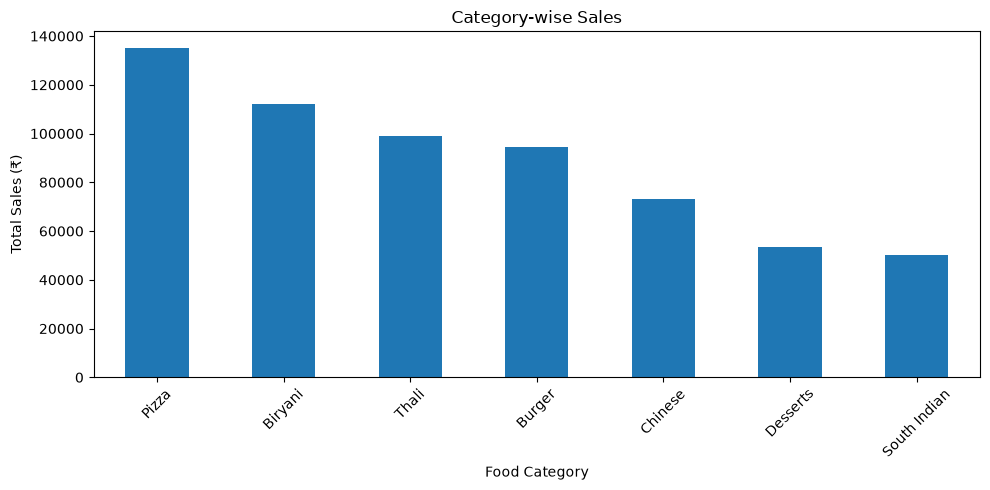

In [11]:
# Category-wise Sales Analysis

category_sales = (
    df.groupby("Category")["Total_Amount"]
      .sum()
      .sort_values(ascending=False)
)

print("Category-wise Sales:")
print(category_sales)

# Bar Chart
plt.figure(figsize=(10, 5))
category_sales.plot(kind="bar")

plt.title("Category-wise Sales")
plt.xlabel("Food Category")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 5 Food Items by Sales:
Item
Paneer Pizza       44264
Veg Biryani        42195
Paneer Biryani     41501
Veg Thali          35253
Farmhouse Pizza    34064
Name: Total_Amount, dtype: int64


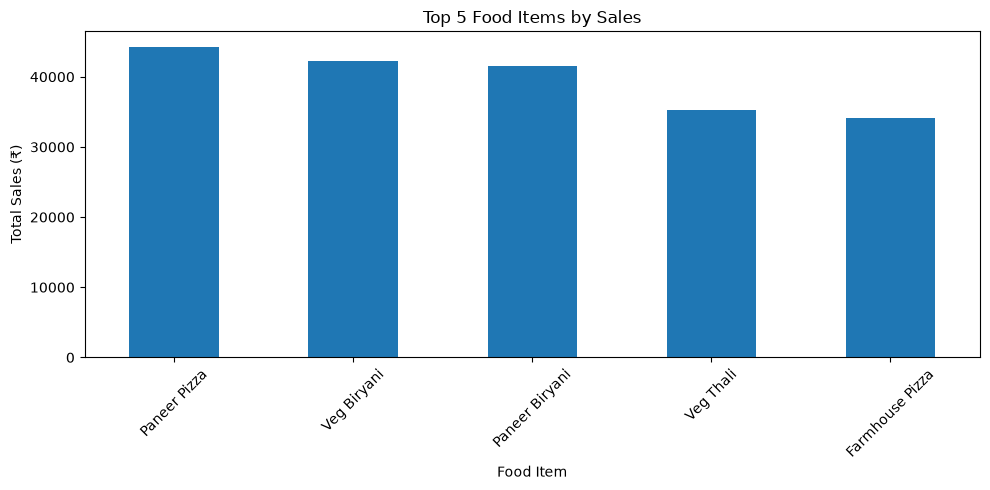

In [12]:
# Top 5 Food Items by Sales

top_items = (
    df.groupby("Item")["Total_Amount"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
)

print("Top 5 Food Items by Sales:")
print(top_items)

# Bar Chart
plt.figure(figsize=(10, 5))
top_items.plot(kind="bar")

plt.title("Top 5 Food Items by Sales")
plt.xlabel("Food Item")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Payment Mode Usage:
Payment_Mode
UPI     351
Cash    333
Card    316
Name: count, dtype: int64


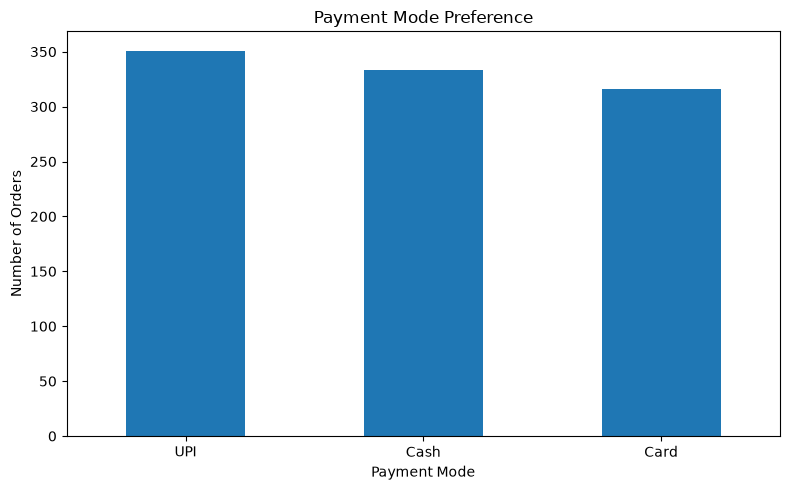

In [13]:
# Payment Mode Analysis

payment_counts = df["Payment_Mode"].value_counts()

print("Payment Mode Usage:")
print(payment_counts)

# Bar Chart
plt.figure(figsize=(8, 5))
payment_counts.plot(kind="bar")

plt.title("Payment Mode Preference")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

City-wise Orders:
City
Nagpur    215
Nashik    201
Mumbai    198
Pune      198
Thane     188
Name: count, dtype: int64


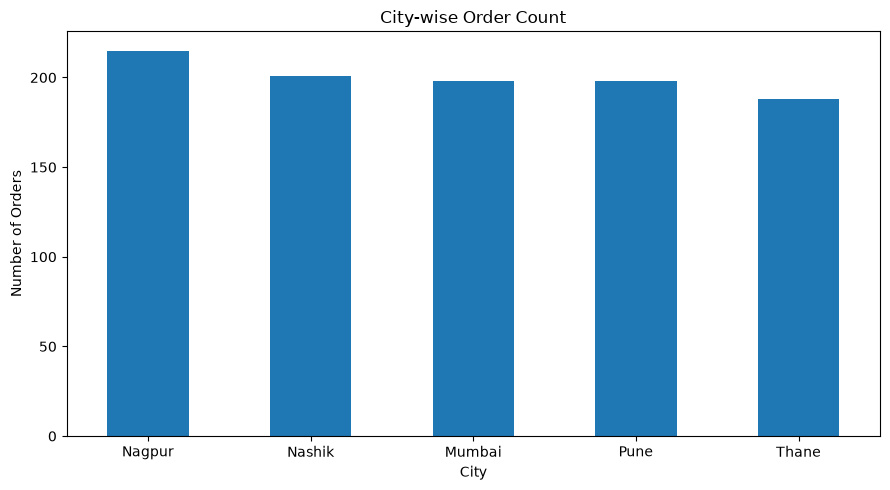

In [14]:
# City-wise Order Analysis

city_orders = (
    df["City"]
    .value_counts()
    .sort_values(ascending=False)
)

print("City-wise Orders:")
print(city_orders)

# Bar Chart
plt.figure(figsize=(9, 5))
city_orders.plot(kind="bar")

plt.title("City-wise Order Count")
plt.xlabel("City")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Monthly Sales:
Month
January      47217
February     42097
March        62664
April        39874
May          41985
June         54671
July         53652
August       56444
September    63446
October      50088
November     53131
December     52307
Name: Total_Amount, dtype: int64


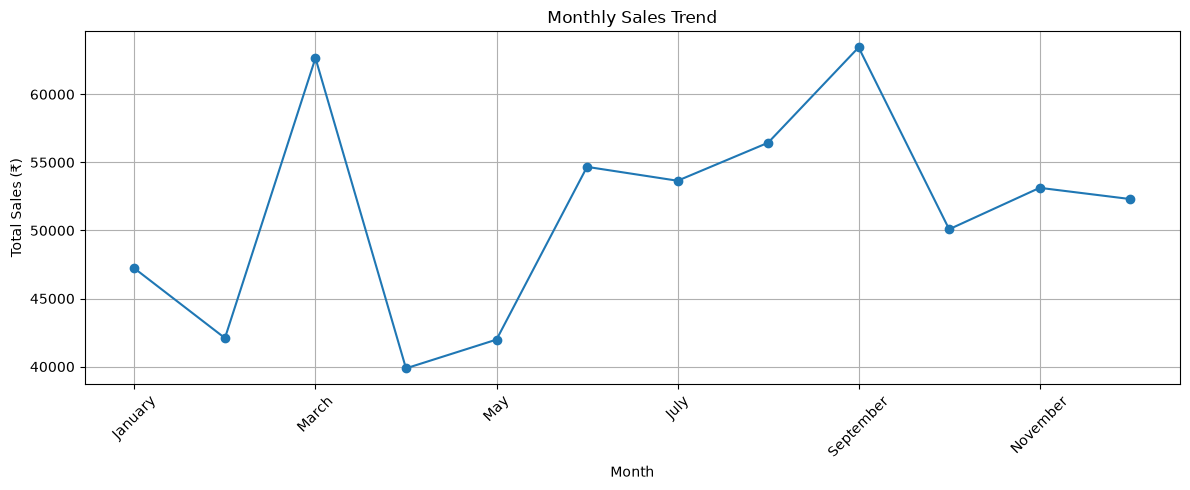

In [15]:
# Monthly Sales Trend

df["Month"] = df["Order_Date"].dt.month_name()

monthly_sales = (
    df.groupby("Month")["Total_Amount"]
      .sum()
)

# Arrange months in correct order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_sales = monthly_sales.reindex(month_order)

print("Monthly Sales:")
print(monthly_sales)

# Line Chart
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

===== DELIVERY PERFORMANCE =====
Average Delivery Time : 41.99 minutes

Order Status:
Order_Status
Delivered    762
Cancelled    238
Name: count, dtype: int64

Cancelled Orders      : 238
Cancellation Rate     : 23.80%


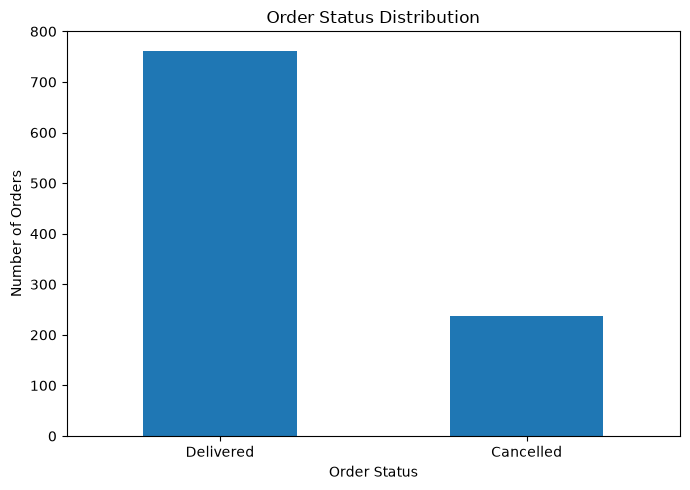

In [16]:
# Delivery Performance Analysis

average_delivery_time = df["Delivery_Time_Min"].mean()

order_status = df["Order_Status"].value_counts()

cancelled_orders = (df["Order_Status"] == "Cancelled").sum()
cancellation_rate = (cancelled_orders / len(df)) * 100

print("===== DELIVERY PERFORMANCE =====")
print(f"Average Delivery Time : {average_delivery_time:.2f} minutes")

print("\nOrder Status:")
print(order_status)

print(f"\nCancelled Orders      : {cancelled_orders}")
print(f"Cancellation Rate     : {cancellation_rate:.2f}%")

# Order Status Chart
plt.figure(figsize=(7, 5))
order_status.plot(kind="bar")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

===== CUSTOMER RATING ANALYSIS =====
Average Customer Rating: 4.01 / 5

Rating Distribution:
Rating
3.0    17
3.1    31
3.2    41
3.3    31
3.4    46
3.5    38
3.6    40
3.7    41
3.8    40
3.9    38
4.0    37
4.1    34
4.2    42
4.3    32
4.4    37
4.5    43
4.6    43
4.7    44
4.8    31
4.9    33
5.0    23
Name: count, dtype: int64


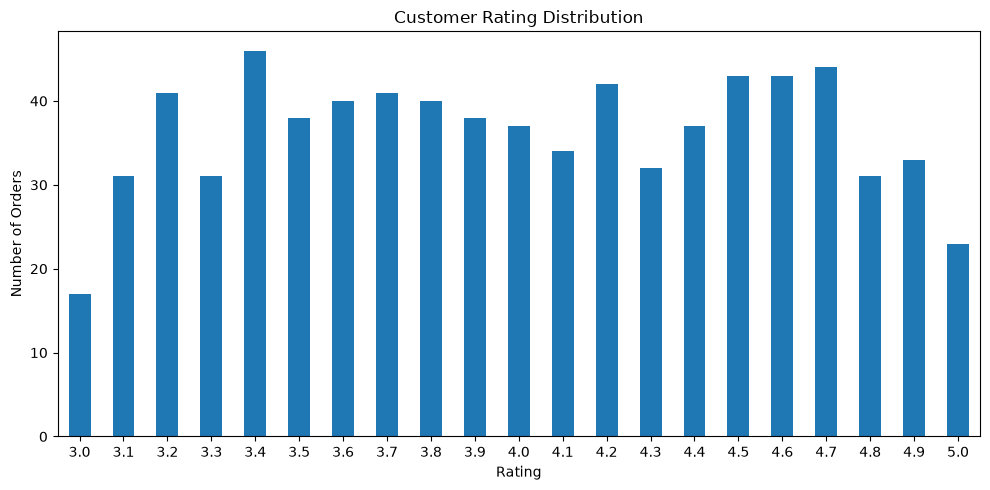

In [17]:
# Customer Rating Analysis

average_rating = df["Rating"].mean()

rating_counts = df["Rating"].value_counts().sort_index()

print("===== CUSTOMER RATING ANALYSIS =====")
print(f"Average Customer Rating: {average_rating:.2f} / 5")

print("\nRating Distribution:")
print(rating_counts)

# Rating Distribution Chart
plt.figure(figsize=(10, 5))
rating_counts.plot(kind="bar")

plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Top 5 Customers by Purchase Value:
Customer_ID  Customer_Name
C1040        Neha             3618
C1154        Sakshi           2959
C1002        Sakshi           2411
C1094        Sakshi           2286
C1129        Riya             2244
Name: Total_Amount, dtype: int64


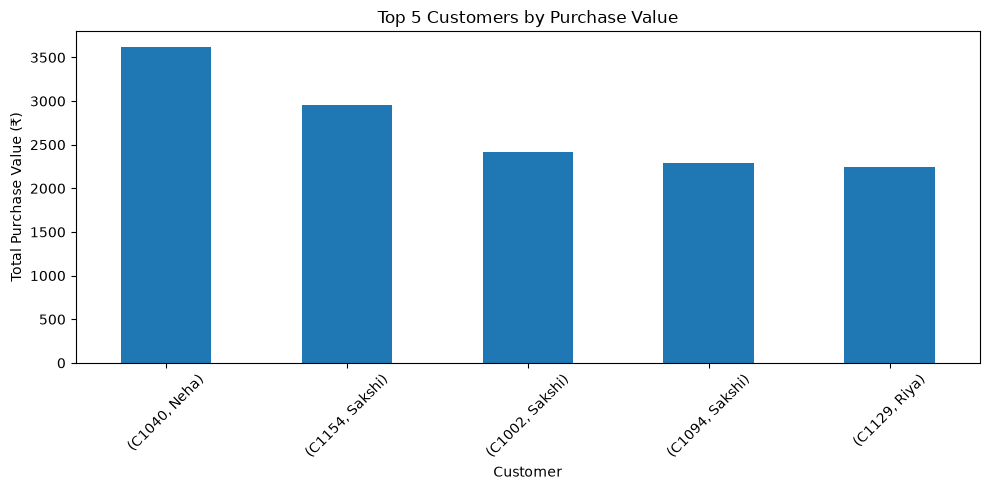

In [18]:
# Top 5 Customers by Purchase Value

top_customers = (
    df.groupby(["Customer_ID", "Customer_Name"])["Total_Amount"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
)

print("Top 5 Customers by Purchase Value:")
print(top_customers)

# Bar Chart
plt.figure(figsize=(10, 5))
top_customers.plot(kind="bar")

plt.title("Top 5 Customers by Purchase Value")
plt.xlabel("Customer")
plt.ylabel("Total Purchase Value (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Total Quantity by Category:
Category
Burger          441
Biryani         382
Thali           369
Desserts        347
Pizza           338
South Indian    337
Chinese         319
Name: Quantity, dtype: int64


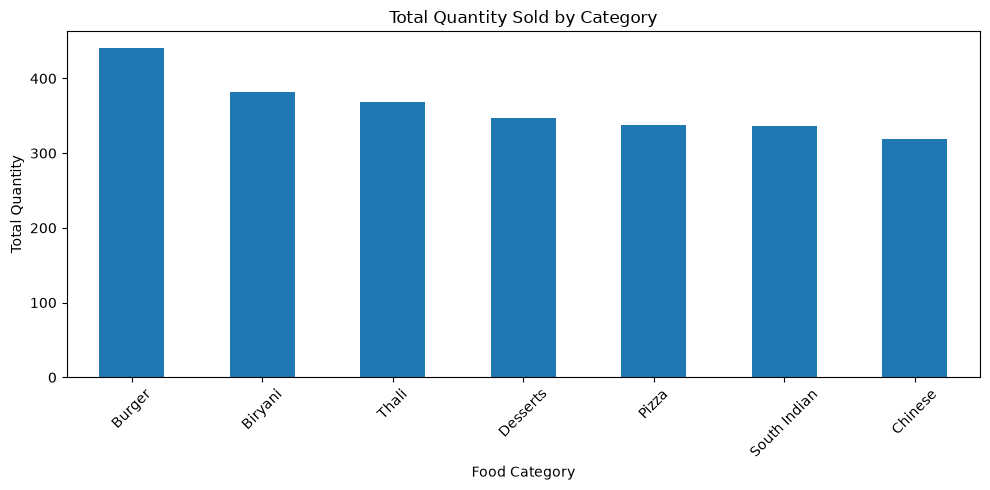

In [19]:
# Total Quantity by Category

quantity_by_category = (
    df.groupby("Category")["Quantity"]
      .sum()
      .sort_values(ascending=False)
)

print("Total Quantity by Category:")
print(quantity_by_category)

# Bar Chart
plt.figure(figsize=(10, 5))
quantity_by_category.plot(kind="bar")

plt.title("Total Quantity Sold by Category")
plt.xlabel("Food Category")
plt.ylabel("Total Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 Restaurants by Sales:
Restaurant
Spice Villa        89066
Urban Bites        85260
Royal Kitchen      82959
Food Hub           78518
Cafe Delight       76706
Quick Eats         72841
Tasty Treats       66338
The Food Corner    65888
Name: Total_Amount, dtype: int64


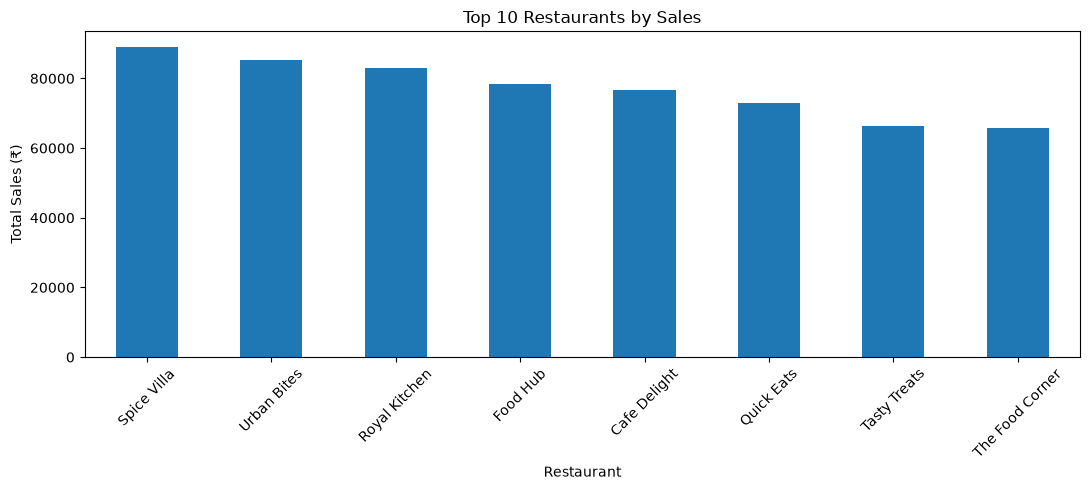

In [20]:
# Restaurant-wise Sales Analysis

restaurant_sales = (
    df.groupby("Restaurant")["Total_Amount"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 Restaurants by Sales:")
print(restaurant_sales)

# Bar Chart
plt.figure(figsize=(11, 5))
restaurant_sales.plot(kind="bar")

plt.title("Top 10 Restaurants by Sales")
plt.xlabel("Restaurant")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 Restaurants by Sales:
Restaurant
Spice Villa        89066
Urban Bites        85260
Royal Kitchen      82959
Food Hub           78518
Cafe Delight       76706
Quick Eats         72841
Tasty Treats       66338
The Food Corner    65888
Name: Total_Amount, dtype: int64


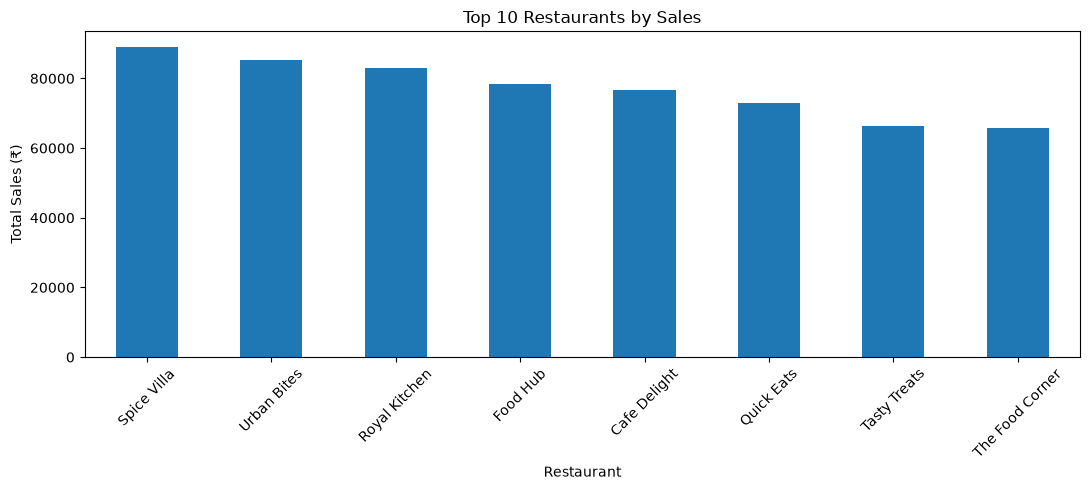

In [21]:
# Restaurant-wise Sales Analysis

restaurant_sales = (
    df.groupby("Restaurant")["Total_Amount"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 Restaurants by Sales:")
print(restaurant_sales)

# Bar Chart
plt.figure(figsize=(11, 5))
restaurant_sales.plot(kind="bar")

plt.title("Top 10 Restaurants by Sales")
plt.xlabel("Restaurant")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
print(df.columns.tolist())

['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'City', 'Restaurant', 'Category', 'Item', 'Quantity', 'Price', 'Total_Amount', 'Payment_Mode', 'Delivery_Time_Min', 'Order_Status', 'Rating', 'Month']


In [23]:
# Delivered Orders Revenue Analysis

delivered_df = df[df["Order_Status"] == "Delivered"]

delivered_revenue = delivered_df["Total_Amount"].sum()
delivered_orders = len(delivered_df)
delivered_aov = delivered_df["Total_Amount"].mean()

print("===== DELIVERED ORDERS ANALYSIS =====")
print(f"Delivered Orders       : {delivered_orders}")
print(f"Delivered Revenue      : ₹{delivered_revenue:,.2f}")
print(f"Delivered Average AOV  : ₹{delivered_aov:,.2f}")

===== DELIVERED ORDERS ANALYSIS =====
Delivered Orders       : 762
Delivered Revenue      : ₹477,333.00
Delivered Average AOV  : ₹626.42


In [24]:
# Final Business Summary

print("========== FOOD DELIVERY BUSINESS SUMMARY ==========")

print(f"Total Orders              : {len(df):,}")
print(f"Gross Order Value         : ₹{df['Total_Amount'].sum():,.2f}")
print(f"Total Quantity Sold       : {df['Quantity'].sum():,}")
print(f"Average Order Value       : ₹{df['Total_Amount'].mean():,.2f}")

print("\n----- Delivery Performance -----")
print(f"Delivered Orders          : {(df['Order_Status'] == 'Delivered').sum():,}")
print(f"Cancelled Orders          : {(df['Order_Status'] == 'Cancelled').sum():,}")
print(f"Cancellation Rate         : {(df['Order_Status'].eq('Cancelled').mean() * 100):.2f}%")
print(f"Average Delivery Time     : {df['Delivery_Time_Min'].mean():.2f} minutes")

print("\n----- Customer Experience -----")
print(f"Average Customer Rating   : {df['Rating'].mean():.2f} / 5")

print("\n----- Top Performers -----")
print(f"Top Category              : {category_sales.index[0]}")
print(f"Top Food Item             : {top_items.index[0]}")
print(f"Top City                  : {city_orders.index[0]}")
print(f"Top Payment Mode          : {payment_counts.index[0]}")
print(f"Top Restaurant            : {restaurant_sales.index[0]}")

print("\n====================================================")

========== FOOD DELIVERY BUSINESS SUMMARY ==========
Total Orders              : 1,000
Gross Order Value         : ₹617,576.00
Total Quantity Sold       : 2,533
Average Order Value       : ₹617.58

----- Delivery Performance -----
Delivered Orders          : 762
Cancelled Orders          : 238
Cancellation Rate         : 23.80%
Average Delivery Time     : 41.99 minutes

----- Customer Experience -----
Average Customer Rating   : 4.01 / 5

----- Top Performers -----
Top Category              : Pizza
Top Food Item             : Paneer Pizza
Top City                  : Nagpur
Top Payment Mode          : UPI
Top Restaurant            : Spice Villa

